# Modeling Epilepsy
The main goal of this tutorial is to provide a clear understanding of how we can reproduce clinically relevant scenarios such as the propagation of an epileptic seizure in the human brain and possible surgical resection of brain regions to restore the dynamics.



In [1]:
!pip install tvb-library

Defaulting to user installation because normal site-packages is not writeable


[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: C:\Users\verga\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
!pip install tvb-framework

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: C:\Users\verga\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
%pylab nbagg
from tvb.simulator.lab import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## The Epileptor Model
The Epileptor is a phenomenological neural mass model able to reproduce epileptic seizure dynamics such as recorded with intracranial EEG electrodes (see Jirsa_et_al, 2014).

In [4]:
# Create an Epileptor model instance
epileptor = models.Epileptor()

## Region based simulation of a temporal lobe seizure

We will model a patient with temporal lobe epilepsy (TLE). We will set different values of epileptogenicity x0
 parameter in the Epileptor according to the region positions, thereby introducing heterogeneities in the network parameters. We set the right limbic areas (right hippocampus (rHC, region 47), parahippocampus (rPHC, region 62) and amygdala (rAMYG, region 40)) as epileptic zones. We also add two lesser epileptogenic regions: the superior temporal cortex (rTCI, region 69) and the ventral temporal cortex (rTCV, region 72).

In other words, we assign to all the nodes the Dynamics for which x0
 has a value of value of −2.2
. We apply the epileptogenic configuration (−1.6
) to the right limbic areas.

Additionally, we chose which kind of coupling we want (between the fast variable (Kvf), the spike-and-wave events (Kf), or the slow permittive coupling (Ks)). Here we use Kf and Ks of them.

Finally, we also slow-down the dynamics of the Epileptor by choosing r=0.00015.

**Focal Epilepsy with Short and Frequent Seizures:**

Set
- $k_f$ high to make the seizures fast and frequent.
- Keep $k_s$ ow to allow for a quick recovery.

**Generalized Epilepsy with Slow and Prolonged Seizures:**

- Lower $k_f$ to make the onset of seizures more gradual.
- Increase $k_s$ to simulate a slower and prolonged recovery phase.

In [5]:
epileptors = models.Epileptor(Ks=np.array([-0.2]), Kf=np.array([0.1]), r=np.array([0.00015]))
epileptors.x0 = np.ones((76))*-2.4
epileptors.x0[[62, 47, 40]] = np.ones((3))*-1.6
epileptors.x0[[69, 72]] = np.ones((2))*-1.8

In [6]:
con = connectivity.Connectivity.from_file()

2026-05-15 10:51:33,248 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


In [7]:
coupl = coupling.Difference(a=np.array([1.]))

We use a stochastic integration scheme; the noise is only added on the two variables of the second population (y3, y4)

In [8]:
hiss = noise.Additive(nsig = np.array([0., 0., 0., 0.0003, 0.0003, 0.]))
heunint = integrators.HeunStochastic(dt=0.05, noise=hiss)

In [9]:
# load the default region mapping
rm = region_mapping.RegionMapping.from_file()

#Initialise some Monitors with period in physical time
mon_tavg = monitors.TemporalAverage(period=1.)
mon_EEG = monitors.EEG.from_file()
mon_EEG.region_mapping=rm
mon_EEG.period=1.


#Bundle them
what_to_watch = (mon_tavg, mon_EEG)

In [10]:
#Initialise a Simulator -- Model, Connectivity, Integrator, and Monitors.
sim = simulator.Simulator(model=epileptors, connectivity=con,
                          coupling=coupl,
                          integrator=heunint, monitors=what_to_watch)

sim.configure()

2026-05-15 10:51:33,436 - INFO - tvb.simulator.monitors - Projection configured gain shape (65, 76)


In [11]:
(ttavg, tavg), (teeg, eeg) = sim.run(simulation_length=10000)

In [12]:
# Normalize the time series to have nice plots
tavg /= (np.max(tavg,0) - np.min(tavg,0 ))
eeg /= (np.max(eeg,0) - np.min(eeg,0 ))
eeg -= np.mean(eeg, 0)

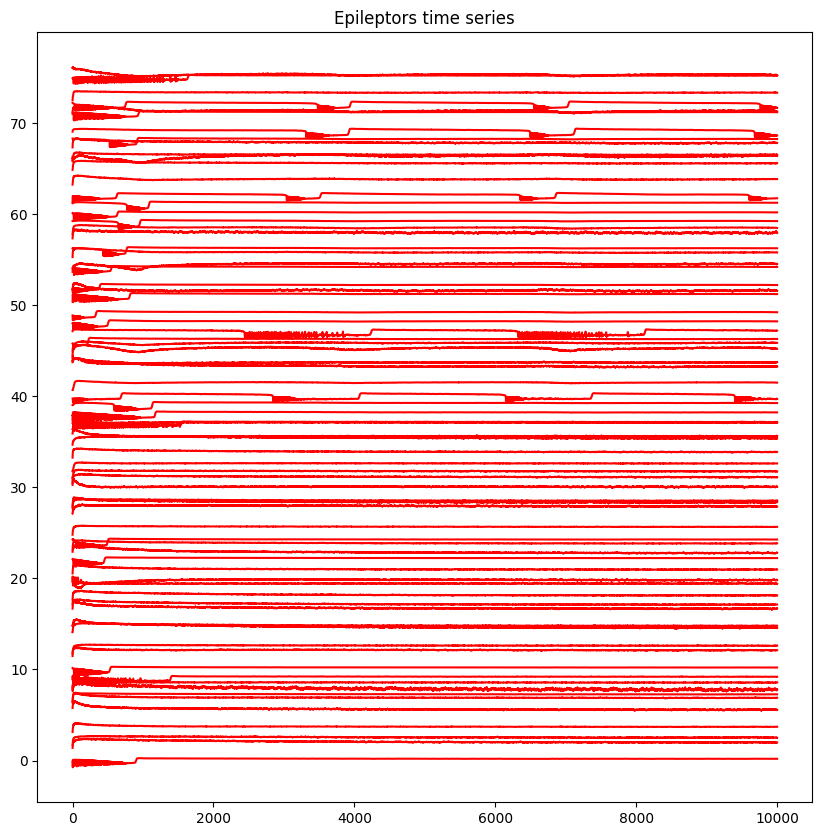

In [13]:
plt.figure(figsize=(10,10))
plt.plot(ttavg[:], tavg[:, 0, :, 0] + np.r_[:76], 'r')
plt.title("Epileptors time series")
plt.show()

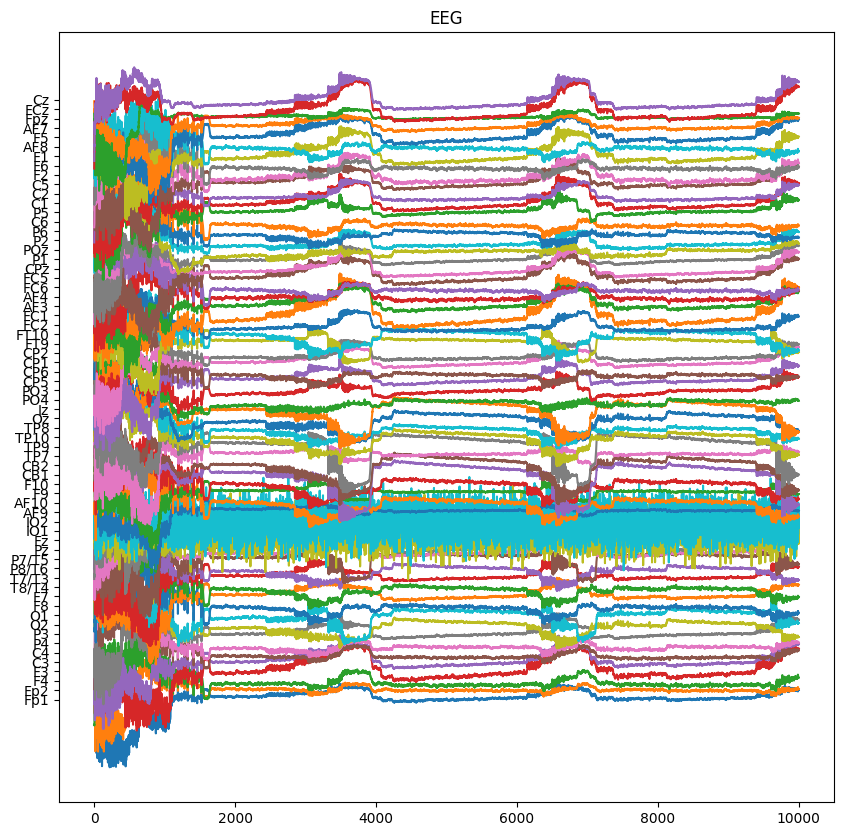

In [14]:
plt.figure(figsize=(10,10))
plt.plot(teeg[:], 10*eeg[:, 0, :, 0] + np.r_[:65])
plt.yticks(np.r_[:65], mon_EEG.sensors.labels)
plt.title("EEG")
plt.show()

## Modeling surgical resection
Surgical resection is used for around 20% of epileptic patient whose seizures are drug- resistant. We will simulate the resection of our EZ.

In [15]:
con = connectivity.Connectivity.from_file()
con.weights[[ 47, 40]] = 0.
con.weights[:, [47, 40]] = 0.

2026-05-15 10:53:18,058 - WARNING - tvb.basic.readers - File 'hemispheres' not found in ZIP.


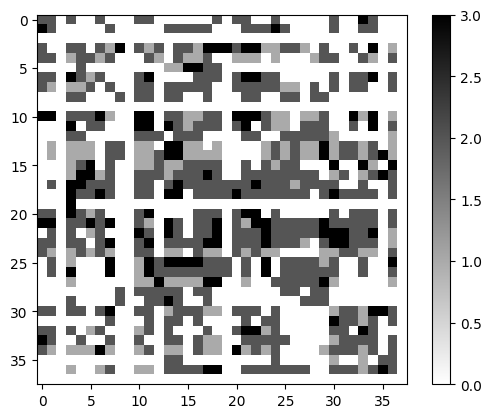

In [16]:
# we plot only the right hemisphere
# the lines and columns set to 0 are clearly visible
plt.figure()
plt.imshow(con.weights[38:, 38:], interpolation='nearest', cmap='binary')
plt.colorbar()
plt.show()


In [17]:
coupl = coupling.Difference(a=numpy.array([1.]))
hiss = noise.Additive(nsig = numpy.array([0., 0., 0., 0.0003, 0.0003, 0.]))
heunint = integrators.HeunStochastic(dt=0.05, noise=hiss)
mon_tavg = monitors.TemporalAverage(period=1.)

In [18]:
epileptors = models.Epileptor(Ks=np.array([-0.2]), Kf=np.array([0.1]), r=np.array([0.00015]))
epileptors.x0 = np.ones((76))*-2.4
epileptors.x0[[69, 72]] = np.ones((2))*-1.8
sim = simulator.Simulator(model=epileptors, connectivity=con,
                          coupling=coupl,
                          integrator=heunint, monitors=(mon_tavg,))

sim.configure();

In [19]:
(ttavg, tavg), = sim.run(simulation_length=10000)

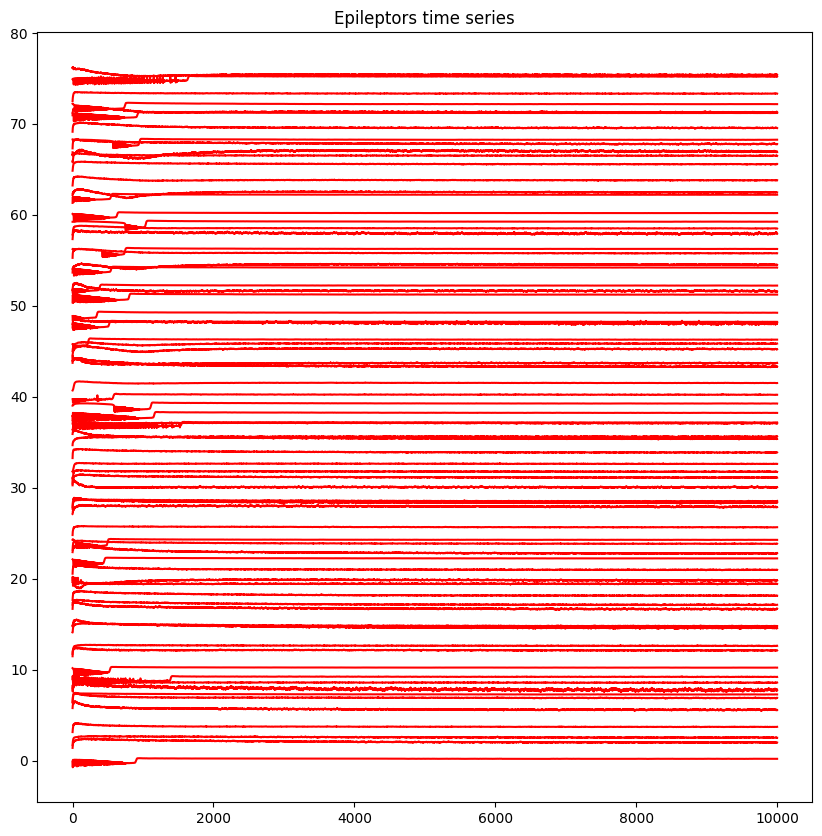

In [20]:
# normalize the time series
tavg /= (np.max(tavg,0) - np.min(tavg,0 ))

plt.figure(figsize=(10,10))
plt.plot(ttavg[:], tavg[:, 0, :, 0] + np.r_[:76], 'r')
plt.title("Epileptors time series")
plt.show()